# DSCI 552 - Homework 4

**Name:** Chen Zhu  
**GitHub username:** ChenZhu50  
**USC ID:** 2370790492


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from scipy.stats import norm
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler, MinMaxScaler, label_binarize
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, roc_curve, roc_auc_score

data_path = '../data/AReM'
activities = ['bending1', 'bending2', 'cycling', 'lying', 'sitting', 'standing', 'walking']
cols = ['time', 'avg_rss12', 'var_rss12', 'avg_rss13', 'var_rss13', 'avg_rss23', 'var_rss23']

## 1. Load data (same as HW3)


In [2]:
# loader from HW3
def load_file(path):
    rows = []
    with open(path, encoding='utf-8-sig') as f:
        for line in f:
            line = line.strip()
            if line == '' or line.startswith('#'):
                continue
            line = line.replace(',', ' ')
            rows.append([float(v) for v in line.split()])
    return pd.DataFrame(rows, columns=cols)

data = []
for act in activities:
    files = [f for f in os.listdir(os.path.join(data_path, act)) if f.endswith('.csv')]
    files = sorted(files, key=lambda f: int(f.replace('dataset', '').replace('.csv', '')))
    for f in files:
        num = int(f.replace('dataset', '').replace('.csv', ''))
        data.append((act, num, load_file(os.path.join(data_path, act, f))))

split = []
for act, num, df in data:
    if act in ['bending1', 'bending2']:
        split.append('test' if num <= 2 else 'train')
    else:
        split.append('test' if num <= 3 else 'train')
split = np.array(split)
labels = np.array([act for act, num, df in data])
y_bin = np.array([1 if act in ['bending1', 'bending2'] else 0 for act, num, df in data])

train = split == 'train'
test = split == 'test'
y_train, y_test = y_bin[train], y_bin[test]
ym_train, ym_test = labels[train], labels[test]
print('files:', len(data), 'train:', train.sum(), 'test:', test.sum())
print('bending in train:', y_train.sum())

files: 88 train: 69 test: 19
bending in train: 9


### Features for l parts

Same 7 statistics as HW3, but now each time series is cut into l parts first (np.array_split, so sitting dataset8 with 479 rows still works).


In [3]:
def get_features(l):
    rows = []
    for act, num, df in data:
        row = {}
        parts = np.array_split(df[cols[1:]].values, l)
        for j in range(l):
            for i in range(6):
                s = parts[j][:, i]
                name = str(i + 1) + '_s' + str(j + 1)
                row['min' + name] = s.min()
                row['max' + name] = s.max()
                row['mean' + name] = s.mean()
                row['median' + name] = np.median(s)
                row['std' + name] = s.std(ddof=1)
                row['q1' + name] = np.quantile(s, 0.25)
                row['q3' + name] = np.quantile(s, 0.75)
        rows.append(row)
    return pd.DataFrame(rows)

# computing this every time is slow so save all l
features = {}
for l in range(1, 21):
    features[l] = get_features(l)
features[1].head()

,min1_s1,max1_s1,mean1_s1,median1_s1,std1_s1,q11_s1,q31_s1,min2_s1,max2_s1,mean2_s1,...,std5_s1,q15_s1,q35_s1,min6_s1,max6_s1,mean6_s1,median6_s1,std6_s1,q16_s1,q36_s1
0,37.25,45.00,40.624792,40.50,1.476967,39.25,42.00,0.0,1.30,0.358604,...,2.188449,33.0000,36.00,0.0,1.92,0.570583,0.43,0.582915,0.0,1.30
1,38.00,45.67,42.812812,42.50,1.435550,42.00,43.67,0.0,1.22,0.372437,...,1.995255,32.0000,34.50,0.0,3.11,0.571083,0.43,0.601010,0.0,1.30
2,35.00,47.40,43.954500,44.33,1.558835,43.00,45.00,0.0,1.70,0.426250,...,1.999604,35.3625,36.50,0.0,1.79,0.493292,0.43,0.513506,0.0,0.94
3,33.00,47.75,42.179812,43.50,3.670666,39.15,45.00,0.0,3.00,0.696042,...,3.849448,30.4575,36.33,0.0,2.18,0.613521,0.50,0.524317,0.0,1.00
4,33.00,45.75,41.678063,41.75,2.243490,41.33,42.75,0.0,2.83,0.535979,...,2.411026,28.4575,31.25,0.0,1.79,0.383292,0.43,0.389164,0.0,0.50


## 2(a)(i) Scatter plots

Using mean, std and max (my 3 features from HW3) of time series 1, 2 and 6, training data only.


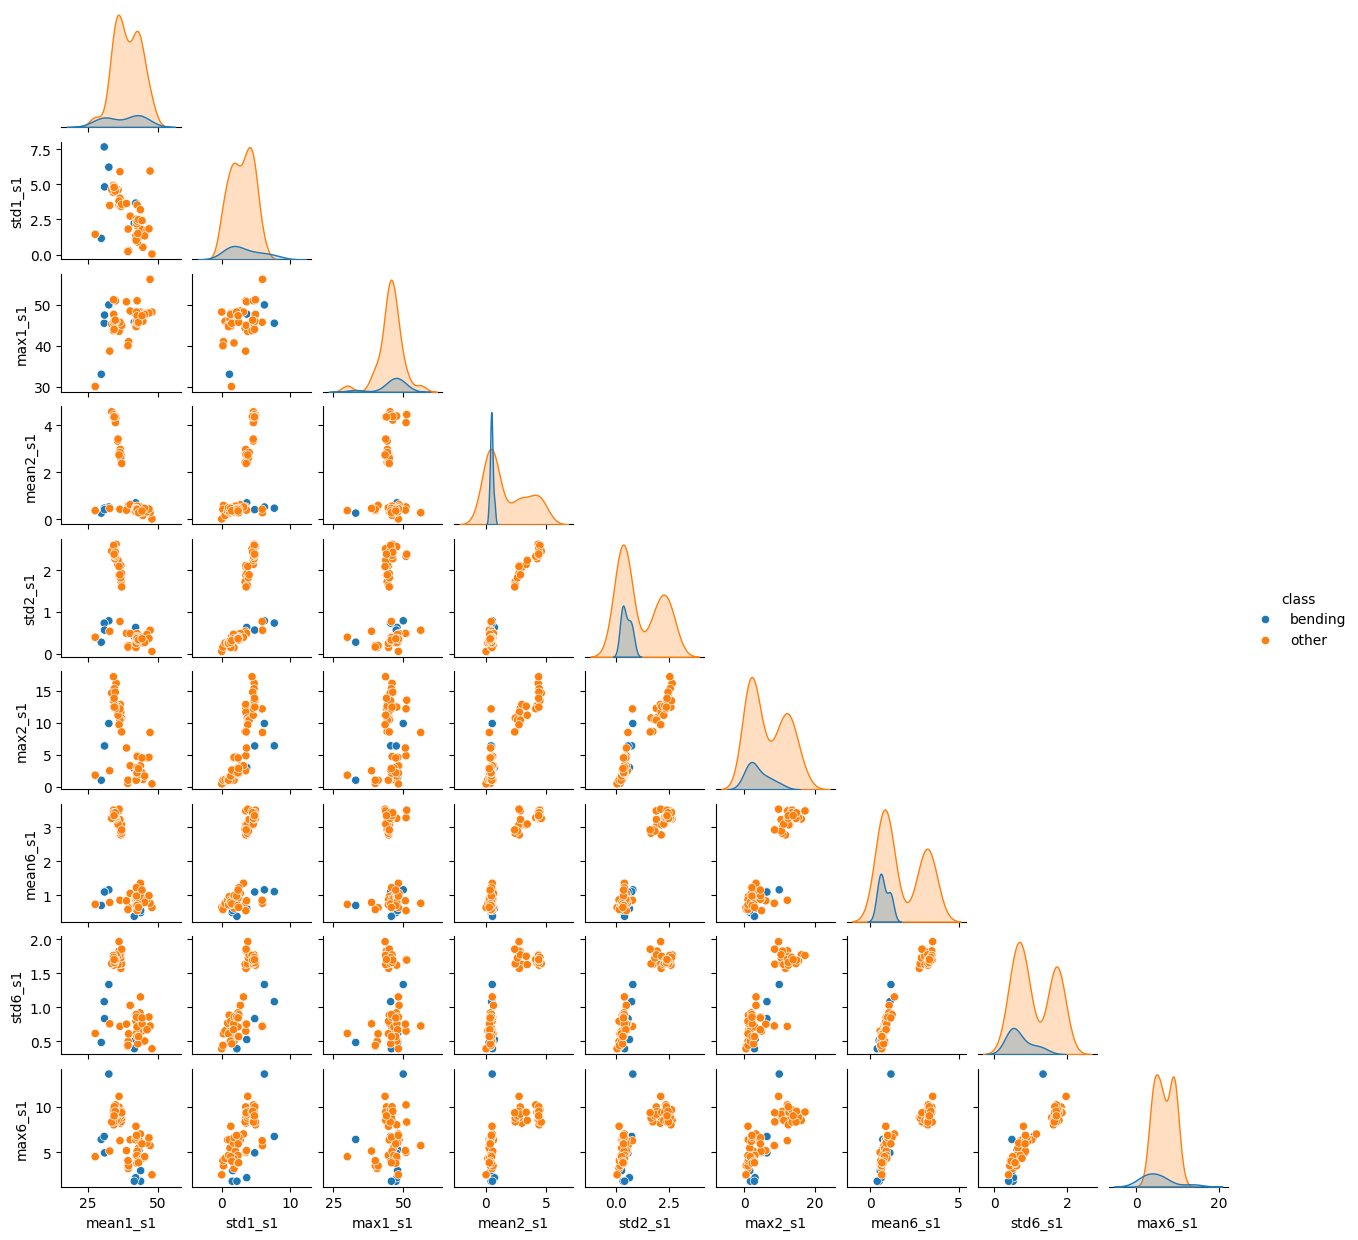

In [4]:
def scatter_plot(l):
    names = []
    for j in range(1, l + 1):
        for i in [1, 2, 6]:
            for stat in ['mean', 'std', 'max']:
                names.append(stat + str(i) + '_s' + str(j))
    df = features[l][train][names].copy()
    df['class'] = np.where(y_train == 1, 'bending', 'other')
    sns.pairplot(df, vars=names, hue='class', corner=True, height=1.4)
    plt.show()

scatter_plot(1)

## 2(a)(ii) l = 2


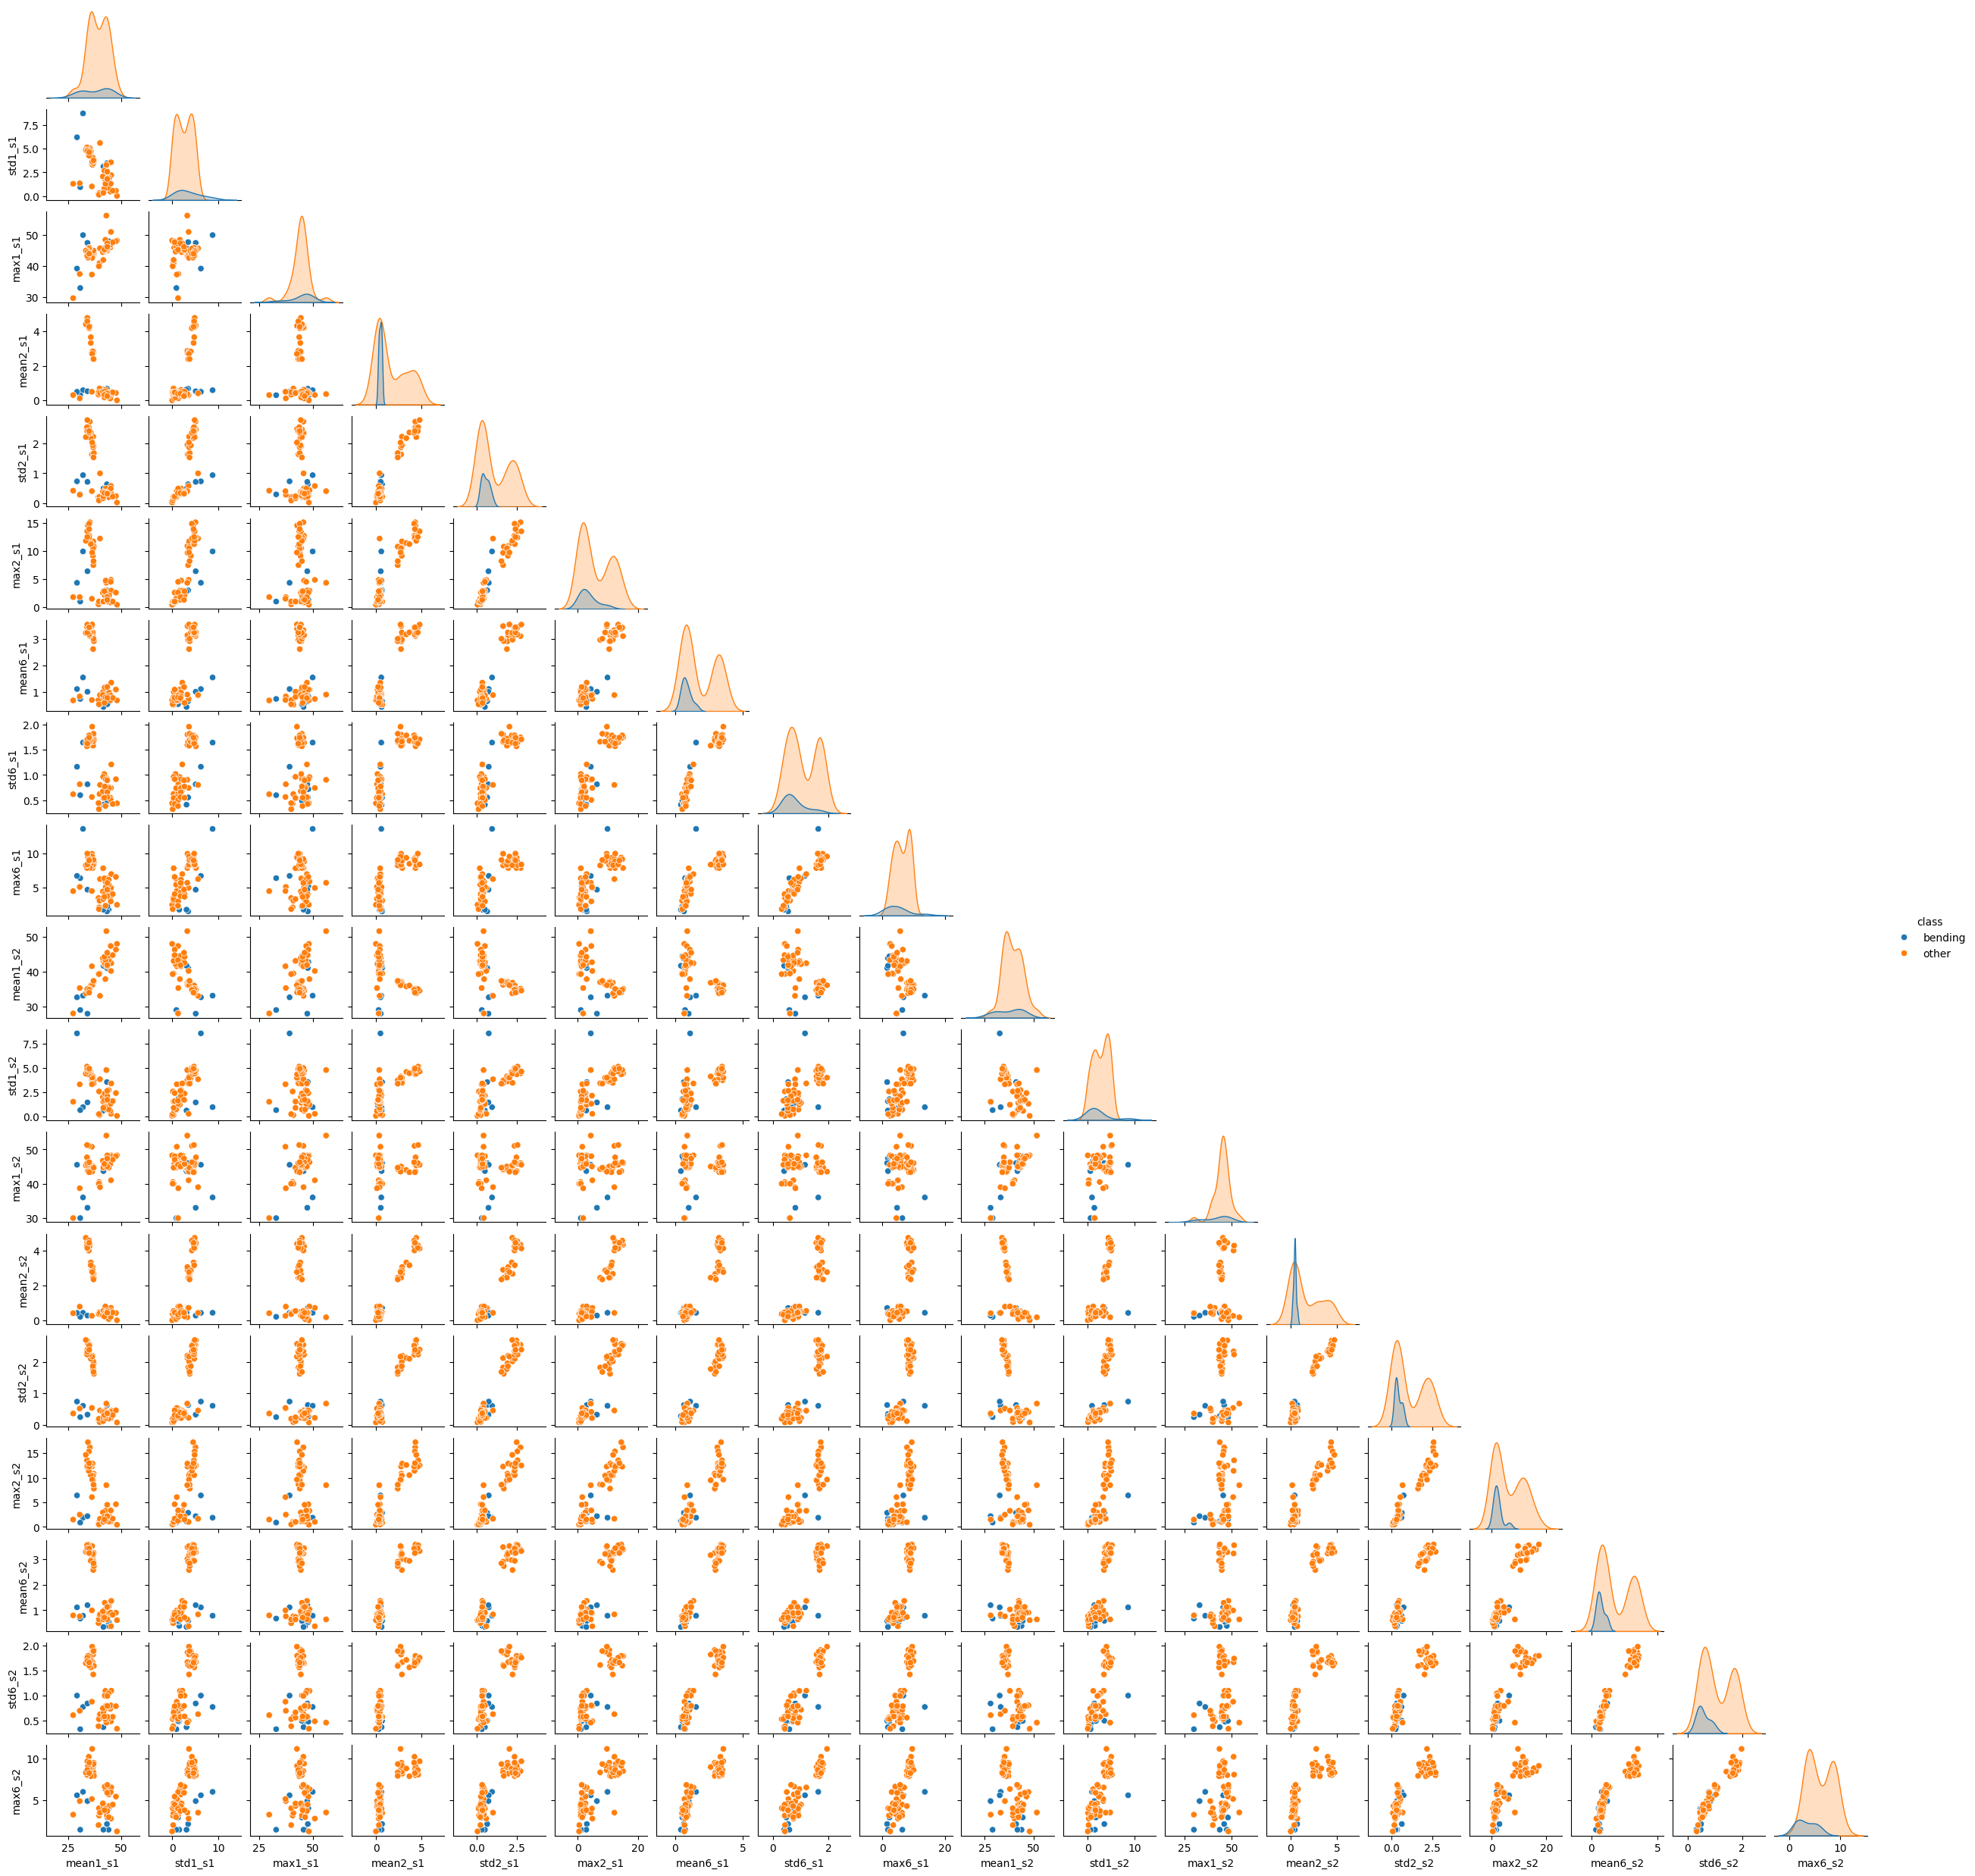

In [5]:
scatter_plot(2)

Not really better with 2 parts. In most plots the bending points still overlap with the lower cluster of the 'other' points (easiest to see for mean2, std2 and mean6), and the s1 and s2 plots look almost the same.


## 2(a)(iii) Choosing l and p

The question allows RFE instead of p-values, so I used RFE. The feature selection has to be inside each CV fold (the Pipeline does this), otherwise the selection already saw the validation fold and the CV accuracy is too optimistic. I used stratified 5-fold because there are only 9 bending files in train.


In [6]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=552)

rfe_results = []
for l in range(1, 21):
    X = features[l][train]
    for p in [1, 2, 3, 4, 5, 10, 15, 20]:
        model = Pipeline([('scale', StandardScaler()),
                          ('rfe', RFE(LogisticRegression(penalty=None, max_iter=400), n_features_to_select=p)),
                          ('lr', LogisticRegression(penalty=None, max_iter=400))])
        scores = cross_val_score(model, X, y_train, cv=cv)
        rfe_results.append([l, p, scores.mean()])

rfe_results = pd.DataFrame(rfe_results, columns=['l', 'p', 'cv_acc'])
best = rfe_results.loc[rfe_results.cv_acc.idxmax()]
best_l, best_p = int(best.l), int(best.p)
print(best)
rfe_results.sort_values('cv_acc', ascending=False).head(10)

l         18.000000
p          3.000000
cv_acc     0.985714
Name: 138, dtype: float64


,l,p,cv_acc
138,18,3,0.985714
97,13,2,0.971429
149,19,10,0.971429
24,4,1,0.971429
139,18,4,0.971429
16,3,1,0.971429
144,19,1,0.971429
145,19,2,0.971429
136,18,1,0.971429
155,20,4,0.971429


## 2(a)(iv) Train the final model


In [7]:
X_train = features[best_l][train]
X_test = features[best_l][test]
rfe_model = Pipeline([('scale', StandardScaler()),
                      ('rfe', RFE(LogisticRegression(penalty=None, max_iter=400), n_features_to_select=best_p)),
                      ('lr', LogisticRegression(penalty=None, max_iter=400))])
rfe_model.fit(X_train, y_train)

selected = X_train.columns[rfe_model.named_steps['rfe'].support_]
print('selected features:', list(selected))

# p-values from statsmodels on the same standardized features
Z = rfe_model.named_steps['scale'].transform(X_train)[:, rfe_model.named_steps['rfe'].support_]
# default newton crashed with 'Singular matrix' (data is separable, coefs go to infinity and the Hessian becomes singular); bfgs doesn't invert the Hessian
sm_fit = sm.Logit(y_train, sm.add_constant(Z)).fit(method='bfgs', maxiter=400)
print(sm_fit.summary(xname=['const'] + list(selected)))

selected features: ['q15_s3', 'q31_s11', 'std5_s17']
Optimization terminated successfully.
         Current function value: 0.000003
         Iterations: 22
         Function evaluations: 23
         Gradient evaluations: 23
                           Logit Regression Results                           
Dep. Variable:                      y   No. Observations:                   69
Model:                          Logit   Df Residuals:                       65
Method:                           MLE   Df Model:                            3
Date:                Mon, 19 Oct 2026   Pseudo R-squ.:                   1.000
Time:                        23:54:07   Log-Likelihood:            -0.00019934
converged:                       True   LL-Null:                       -26.718
Covariance Type:            nonrobust   LLR p-value:                 1.481e-11
                 coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------

Selected features: q15_s3, q31_s11, std5_s17. With the default Newton method statsmodels crashed with a singular matrix error, so I used BFGS. It says "converged", but only because the log-likelihood is already about 0, and it warns about complete quasi-separation. The coefficients/p-values in the table are not meaningful (huge std errors, every p-value is 1.0).

The sklearn model that I actually use for prediction has intercept -13.85 and coefficients 12.98 (q15_s3), -7.32 (q31_s11), -5.23 (std5_s17) on the standardized features. These are different from the statsmodels table because the data is separable: the MLE doesn't exist, so each optimizer just stops somewhere when the likelihood is close to 1. I only use statsmodels to get p-values, and neither set of coefficients should be interpreted.


## 2(a)(v) Confusion matrix and ROC


RFE train accuracy: 1.0 AUC: 1.0


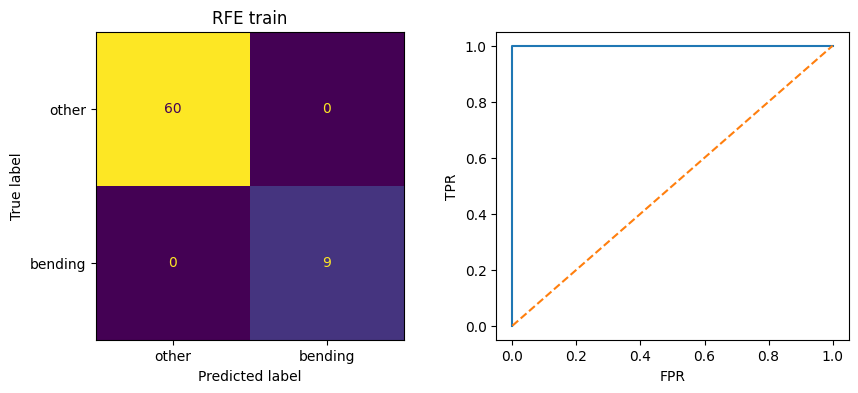

RFE test accuracy: 0.9473684210526315 AUC: 0.8833333333333333


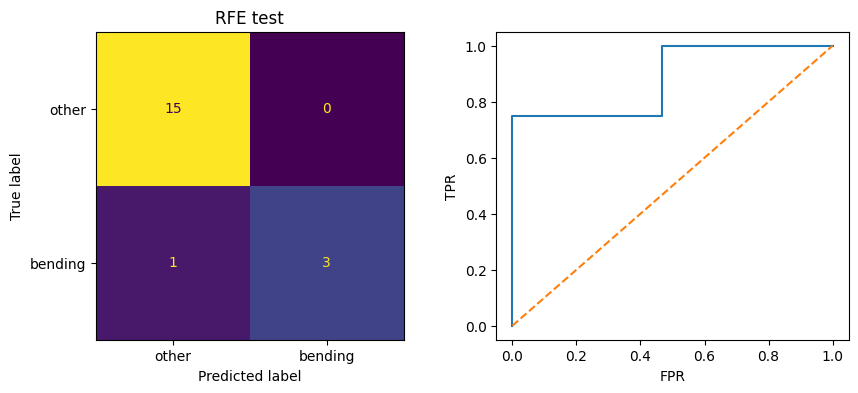

CV accuracy: 0.9857142857142858


In [8]:
def show_results(model, X, y, title):
    prob = model.predict_proba(X)[:, 1]
    pred = model.predict(X)
    print(title, 'accuracy:', accuracy_score(y, pred), 'AUC:', roc_auc_score(y, prob))
    fig, ax = plt.subplots(1, 2, figsize=(10, 4))
    ConfusionMatrixDisplay(confusion_matrix(y, pred), display_labels=['other', 'bending']).plot(ax=ax[0], colorbar=False)
    fpr, tpr, _ = roc_curve(y, prob)
    ax[1].plot(fpr, tpr)
    ax[1].plot([0, 1], [0, 1], '--')
    ax[1].set_xlabel('FPR')
    ax[1].set_ylabel('TPR')
    ax[0].set_title(title)
    plt.show()
    return accuracy_score(y, pred), roc_auc_score(y, prob)

rfe_train = show_results(rfe_model, X_train, y_train, 'RFE train')
rfe_test = show_results(rfe_model, X_test, y_test, 'RFE test')
print('CV accuracy:', best.cv_acc)

Best CV accuracy is 98.57% with l = 18, p = 3. Train accuracy is 100% and test accuracy is 94.74% (1 of 19 test files wrong), test AUC 0.883. The test accuracy is a bit lower than the CV accuracy, which makes sense since (l, p) was chosen to maximize CV accuracy, so the CV number is slightly optimistic. With only 19 test files, one mistake already costs 5.26%.


## 2(a)(vi) Separation

Yes. Training accuracy is 100%, and in 2(a)(iv) statsmodels warns about complete quasi-separation (and Newton's method even fails with a singular matrix). When the classes are separable the MLE doesn't exist: the likelihood keeps going up as the coefficients get bigger, so the coefficients and std errors become huge.


## 2(a)(vii) Case-control sampling

The classes are imbalanced, 9 bending vs 60 other in train. Usual case-control sampling would undersample the 'other' class, but that would leave only 9 + 9 = 18 files, so instead I sampled bending files again with replacement until both classes have 60, then corrected the intercept because the class proportion changed:

$$\hat\beta_0^{*} = \hat\beta_0 + \log\frac{\pi}{1-\pi} - \log\frac{q}{1-q}$$

where $\pi = 9/69$ is the bending proportion in the original train data and $q = 0.5$ after resampling.


pi = 0.13043478260869565 shift = -1.8971199848858813
balanced train accuracy: 1.0 AUC: 1.0


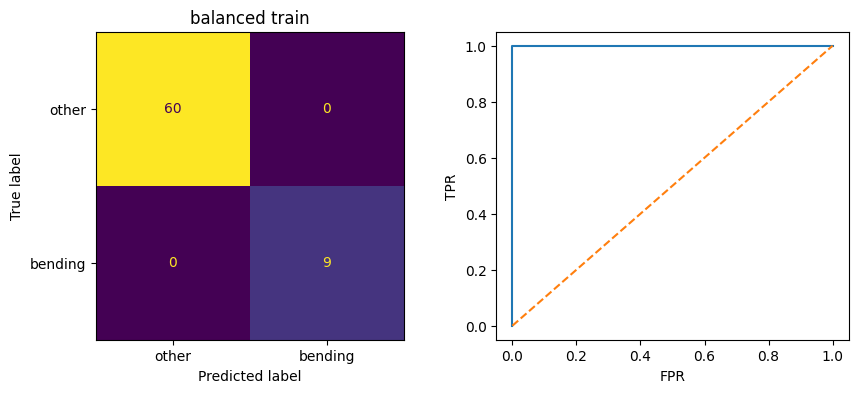

balanced test accuracy: 0.9473684210526315 AUC: 0.8833333333333333


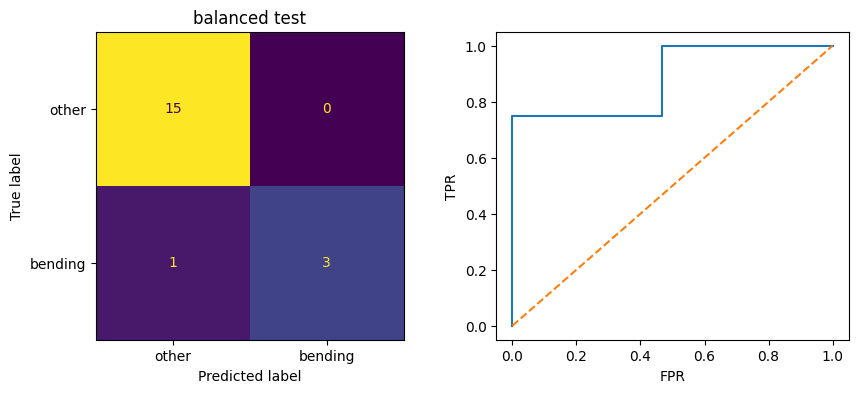

In [9]:
np.random.seed(552)
neg = np.where(y_train == 0)[0]
pos = np.where(y_train == 1)[0]
extra = np.random.choice(pos, len(neg) - len(pos), replace=True)
idx = np.concatenate([neg, pos, extra])

bal_model = Pipeline([('scale', StandardScaler()), ('lr', LogisticRegression(penalty=None, max_iter=400))])
bal_model.fit(X_train[selected].iloc[idx], y_train[idx])

# intercept correction
pi = y_train.mean()
q = 0.5
shift = np.log(pi / (1 - pi)) - np.log(q / (1 - q))
print('pi =', pi, 'shift =', shift)
bal_model.named_steps['lr'].intercept_ += shift

bal_train = show_results(bal_model, X_train[selected], y_train, 'balanced train')
bal_test = show_results(bal_model, X_test[selected], y_test, 'balanced test')

Same as before: train 100%, test 94.74%. Balancing didn't change the predictions here.


## 2(b)(i) L1-penalized logistic regression


l         11.000000
C          1.000000
cv_acc     0.985714
Name: 63, dtype: float64
nonzero coefficients: 8
L1 train accuracy: 1.0 AUC: 1.0


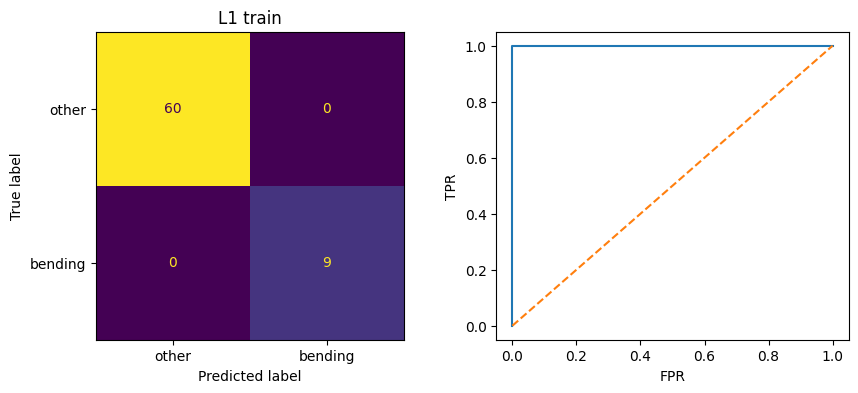

L1 test accuracy: 0.9473684210526315 AUC: 1.0


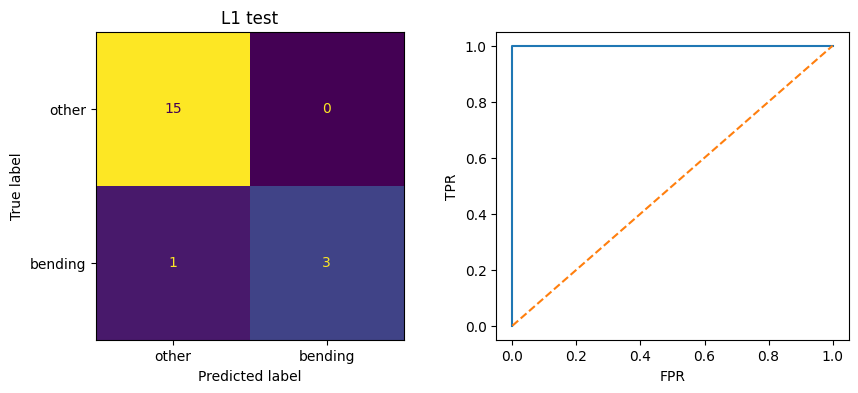

In [10]:
l1_results = []
for l in range(1, 21):
    X = features[l][train]
    for C in [0.001, 0.01, 0.1, 1, 10, 100]:
        model = Pipeline([('scale', StandardScaler()),
                          ('lr', LogisticRegression(penalty='l1', solver='liblinear', C=C, max_iter=5000))])
        scores = cross_val_score(model, X, y_train, cv=cv)
        l1_results.append([l, C, scores.mean()])

l1_results = pd.DataFrame(l1_results, columns=['l', 'C', 'cv_acc'])
best_l1 = l1_results.loc[l1_results.cv_acc.idxmax()]
l1_l, l1_C = int(best_l1.l), best_l1.C
print(best_l1)

l1_model = Pipeline([('scale', StandardScaler()),
                     ('lr', LogisticRegression(penalty='l1', solver='liblinear', C=l1_C, max_iter=5000))])
l1_model.fit(features[l1_l][train], y_train)
print('nonzero coefficients:', np.sum(l1_model.named_steps['lr'].coef_ != 0))
l1_train = show_results(l1_model, features[l1_l][train], y_train, 'L1 train')
l1_test = show_results(l1_model, features[l1_l][test], y_test, 'L1 test')

Best is l = 11, C = 1 with CV accuracy 98.57%, and only 8 coefficients are nonzero. Test accuracy 94.74%, test AUC 1.0.


## 2(b)(ii) L1 vs variable selection


In [11]:
pd.DataFrame([['RFE', best_l, best.cv_acc, rfe_test[0], rfe_test[1]],
              ['L1', l1_l, best_l1.cv_acc, l1_test[0], l1_test[1]]],
             columns=['method', 'l', 'cv_acc', 'test_acc', 'test_auc'])

,method,l,cv_acc,test_acc,test_auc
0,RFE,18,0.985714,0.947368,0.883333
1,L1,11,0.985714,0.947368,1.000000


CV accuracy and test accuracy are the same for both, but L1 has a better test AUC (1.0 vs 0.883). L1 was easier to use since there is only C to tune and the penalty picks the features by itself. With RFE I had to try many p values and refit every time. (I compared with RFE because that's what I used in 2(a).)


## 2(c)(i) Multiclass L1 logistic regression


In [12]:
import warnings
# bending2 has only 4 train files < 5 folds, sklearn warns about this on every CV run (explained below)
warnings.filterwarnings('ignore', message='The least populated class')

# lbfgs gave an error with penalty='l1', so using saga
m_results = []
for l in range(1, 21):
    X = features[l][train]
    for C in [0.01, 0.1, 1, 10]:
        model = Pipeline([('scale', StandardScaler()),
                          ('lr', LogisticRegression(penalty='l1', solver='saga', C=C, max_iter=10000, tol=1e-3))])
        scores = cross_val_score(model, X, ym_train, cv=cv)
        m_results.append([l, C, scores.mean()])

m_results = pd.DataFrame(m_results, columns=['l', 'C', 'cv_acc'])
best_m = m_results.loc[m_results.cv_acc.idxmax()]
m_l, m_C = int(best_m.l), best_m.C
print(best_m)

multi_model = Pipeline([('scale', StandardScaler()),
                        ('lr', LogisticRegression(penalty='l1', solver='saga', C=m_C, max_iter=10000, tol=1e-3))])
multi_model.fit(features[m_l][train], ym_train);

l          1.000000
C         10.000000
cv_acc     0.913187
Name: 3, dtype: float64


multiclass L1 test error: 0.10526315789473684


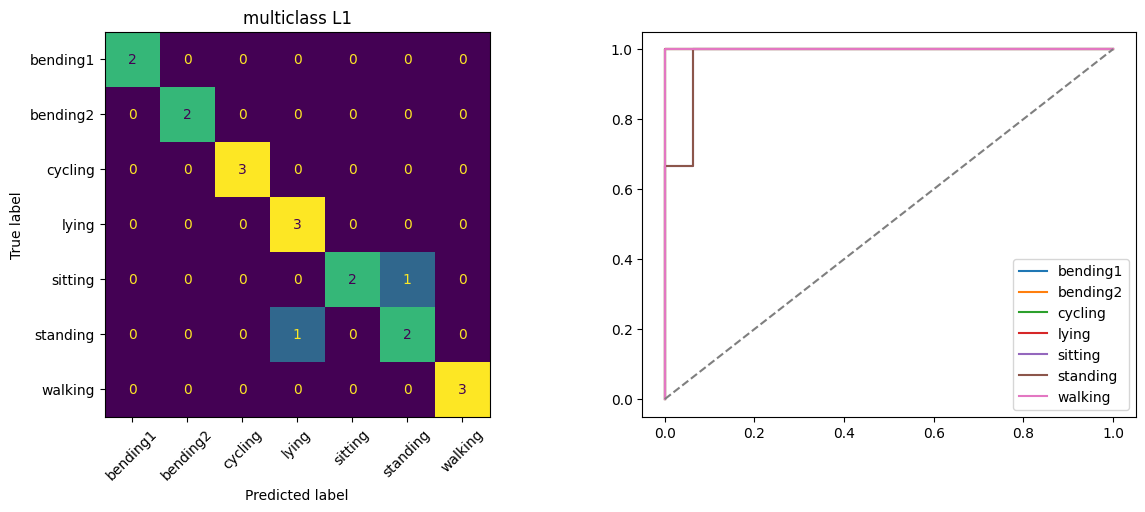

In [13]:
def show_multiclass(model, l, title):
    X = features[l][test]
    pred = model.predict(X)
    prob = model.predict_proba(X)
    err = 1 - accuracy_score(ym_test, pred)
    print(title, 'test error:', err)
    fig, ax = plt.subplots(1, 2, figsize=(14, 5))
    ConfusionMatrixDisplay(confusion_matrix(ym_test, pred, labels=model.classes_),
                           display_labels=model.classes_).plot(ax=ax[0], colorbar=False, xticks_rotation=45)
    # one vs rest ROC for each class
    Y = label_binarize(ym_test, classes=model.classes_)
    aucs = []
    for i, c in enumerate(model.classes_):
        fpr, tpr, _ = roc_curve(Y[:, i], prob[:, i])
        aucs.append(roc_auc_score(Y[:, i], prob[:, i]))
        ax[1].plot(fpr, tpr, label=c)
    ax[1].plot([0, 1], [0, 1], '--')
    ax[1].legend()
    ax[0].set_title(title)
    plt.show()
    return err, np.mean(aucs)

multi_res = show_multiclass(multi_model, m_l, 'multiclass L1')

Best is l = 1, C = 10 (CV accuracy 91.32%), test error 10.53%. sklearn warns that bending2 only has 4 training files, which is less than 5 folds, so not every fold has a bending2 file. I turned that warning off because it printed once for every CV run.


## 2(c)(ii) Naive Bayes


Gaussian best: [1.         0.86923077]  Multinomial best: [5.         0.75274725]
GaussianNB test error: 0.10526315789473684


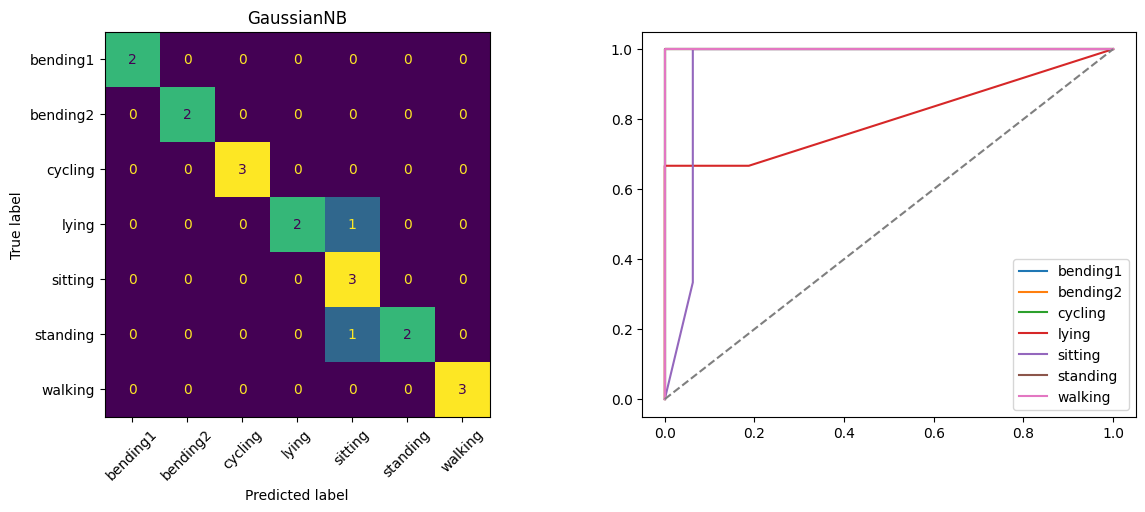

MultinomialNB test error: 0.21052631578947367


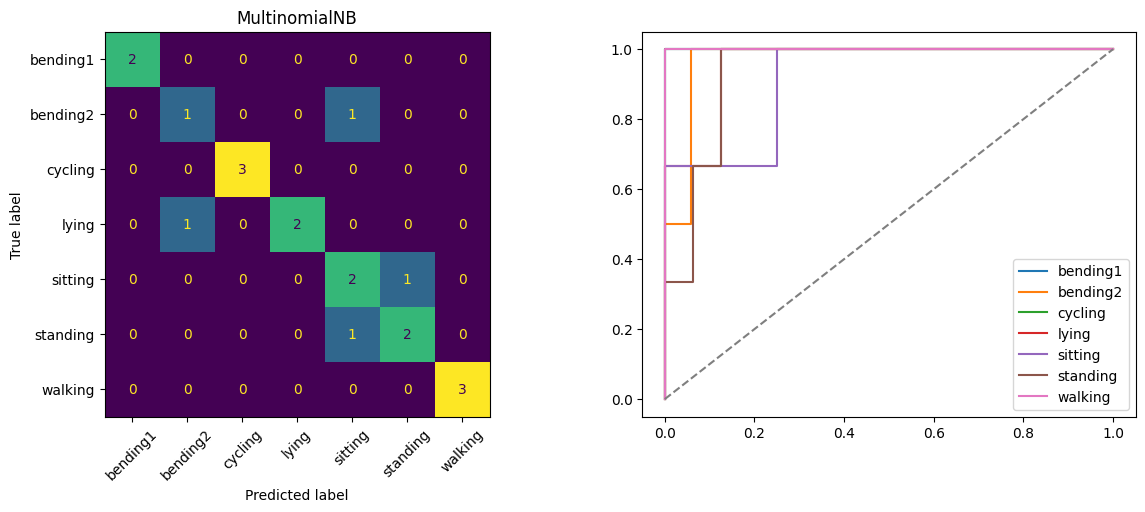

In [14]:
gnb_results = []
mnb_results = []
for l in range(1, 21):
    X = features[l][train]
    gnb = Pipeline([('scale', StandardScaler()), ('nb', GaussianNB())])
    mnb = Pipeline([('scale', MinMaxScaler()), ('nb', MultinomialNB())])  # multinomial needs values >= 0
    gnb_results.append([l, cross_val_score(gnb, X, ym_train, cv=cv).mean()])
    mnb_results.append([l, cross_val_score(mnb, X, ym_train, cv=cv).mean()])

gnb_results = pd.DataFrame(gnb_results, columns=['l', 'cv_acc'])
mnb_results = pd.DataFrame(mnb_results, columns=['l', 'cv_acc'])
g_best = gnb_results.loc[gnb_results.cv_acc.idxmax()]
m_best = mnb_results.loc[mnb_results.cv_acc.idxmax()]
print('Gaussian best:', g_best.values, ' Multinomial best:', m_best.values)

gnb = Pipeline([('scale', StandardScaler()), ('nb', GaussianNB())]).fit(features[int(g_best.l)][train], ym_train)
mnb = Pipeline([('scale', MinMaxScaler()), ('nb', MultinomialNB())]).fit(features[int(m_best.l)][train], ym_train)
gnb_res = show_multiclass(gnb, int(g_best.l), 'GaussianNB')
mnb_res = show_multiclass(mnb, int(m_best.l), 'MultinomialNB')

## 2(c)(iii) Comparison


In [15]:
pd.DataFrame([['L1 logistic', m_l, best_m.cv_acc, multi_res[0], multi_res[1]],
              ['GaussianNB', int(g_best.l), g_best.cv_acc, gnb_res[0], gnb_res[1]],
              ['MultinomialNB', int(m_best.l), m_best.cv_acc, mnb_res[0], mnb_res[1]]],
             columns=['method', 'l', 'cv_acc', 'test_error', 'mean_auc'])

,method,l,cv_acc,test_error,mean_auc
0,L1 logistic,1,0.913187,0.105263,0.994048
1,GaussianNB,1,0.869231,0.105263,0.964286
2,MultinomialNB,5,0.752747,0.210526,0.969013


L1 logistic and GaussianNB both have 10.53% test error and MultinomialNB is worse (21.05%). L1 logistic has the best CV accuracy and mean AUC, so I would use it. MultinomialNB is probably worse because our features are not counts.


## 3. ISLR 4.8.3

Bayes classifier assigns x to the class with the largest $\pi_k f_k(x)$, where $f_k(x) = \frac{1}{\sqrt{2\pi}\sigma_k}\exp\left(-\frac{(x-\mu_k)^2}{2\sigma_k^2}\right)$.

Taking log and dropping $\log\frac{1}{\sqrt{2\pi}}$ (same for every class):

$$\delta_k(x) = -\frac{x^2}{2\sigma_k^2} + \frac{\mu_k x}{\sigma_k^2} - \frac{\mu_k^2}{2\sigma_k^2} - \log\sigma_k + \log\pi_k$$

Since $\sigma_k$ is different for each class, the $x^2$ term does not cancel when we compare two classes, so $\delta_k(x)$ is quadratic in x. (If all $\sigma_k$ were equal the $x^2$ term would be the same for all classes and we'd get LDA, which is linear.)


## 4. ISLR 4.8.7

$$P(Y=\text{yes} \mid X=4) = \frac{0.8\, e^{-(4-10)^2/72}}{0.8\, e^{-(4-10)^2/72} + 0.2\, e^{-(4-0)^2/72}}$$


In [16]:
yes = 0.8 * norm.pdf(4, 10, 6)
no = 0.2 * norm.pdf(4, 0, 6)
print(yes / (yes + no))

0.7518524532975261


P(dividend | X = 4) is about 0.752.


## 5. AI Usage

“I used RFE to select features before running cross-validation, and the accuracy seems suspiciously high. Is this approach valid?”

“After oversampling the bending class to 60 samples, how should I adjust the intercept, and why is this adjustment necessary?”

“RFE and L1-regularized logistic regression have the same test accuracy, but their AUCs are 0.883 and 1.0, respectively. How can I explain this?”

Claude was also used to fix the statsmodels "Singular matrix" error in 2(a)(iv) (switching to BFGS), to hide the repeated sklearn warning in 2(c)(i), and to check that my written answers match the outputs (it revised the wording in 2(a)(ii), (iv), (v), (vi), (vii) and 2(c)(i)).
